# Exact near field and the radiation-zone approximation

The same finite planar aperture is projected onto Cartesian target planes with the exact finite-distance projector. At each target we also evaluate the far-field coefficient in its radial direction, then apply `exp(ikr)/r`. The plane-wise complex vector errors show where that asymptotic field becomes accurate. This is a controlled finite-aperture projection comparison; the open, truncated plane is not an exact Maxwell source.

E/H are plotted in V/m and A/m. Intensity maps show `|E|²` with one shared color scale, as a field-intensity proxy rather than Poynting flux. Phase errors are meaningful only where the reference field is sufficiently strong. Separately, if CUDA and Triton are available, an optional complex64 exact-projector comparison reports backend agreement; it does not measure far-field approximation error.

In [ ]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
repo_root = next(
    (p for p in (cwd, *cwd.parents) if (p / "core/nearfield").is_dir()), None
)
if repo_root is None:
    raise RuntimeError("Could not locate the MAPS repository root")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
if str(repo_root / "examples/nearfield") not in sys.path:
    sys.path.insert(0, str(repo_root / "examples/nearfield"))

import math
import torch
import matplotlib.pyplot as plt
from core.nearfield import make_planar_surface, project_nearfield, project_farfield, C_0
from core.nearfield.observations import direction_cosines
from notebook_utils import (
    field_components,
    field_comparison,
    error_summary,
    show_errors,
    benchmark_methods,
    show_benchmarks,
    surface_copy,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
REAL, COMPLEX = torch.float64, torch.complex128
FREQUENCY_HZ = torch.tensor([193.4e12], dtype=REAL, device=DEVICE)
K = 2 * math.pi * FREQUENCY_HZ / C_0
WAVELENGTH_M = C_0 / FREQUENCY_HZ[0]
print(
    f"device={DEVICE}; wavelength={WAVELENGTH_M.item()*1e6:.4f} µm; fields use {COMPLEX}"
)

device=cuda; wavelength=1.5501 µm; fields use torch.complex128


In [ ]:
# Prescribed Gaussian E/H aperture. Build all reference fields in double precision.
source_n = 21 if DEVICE.type == "cuda" else 15
source_axis_m = torch.linspace(-1.5e-6, 1.5e-6, source_n, dtype=REAL, device=DEVICE)
y_s, x_s = torch.meshgrid(source_axis_m, source_axis_m, indexing="ij")
aperture = torch.exp(-((x_s / 1.0e-6) ** 2 + (y_s / 0.9e-6) ** 2)).to(COMPLEX)
E_source = torch.zeros((1, source_n, source_n, 3), dtype=COMPLEX, device=DEVICE)
H_source = torch.zeros_like(E_source)
E_source[0, ..., 0] = aperture
H_source[0, ..., 1] = aperture / 376.730313668
surface = make_planar_surface(
    origin_m=torch.zeros(3, dtype=REAL, device=DEVICE),
    u_axis=torch.tensor([1.0, 0.0, 0.0], dtype=REAL, device=DEVICE),
    v_axis=torch.tensor([0.0, 1.0, 0.0], dtype=REAL, device=DEVICE),
    u_coordinates_m=source_axis_m,
    v_coordinates_m=source_axis_m,
    electric_fields=E_source,
    magnetic_fields=H_source,
    frequencies_hz=FREQUENCY_HZ,
)

target_n = 21 if DEVICE.type == "cuda" else 15
plane_axis_m = torch.linspace(-3.0e-6, 3.0e-6, target_n, dtype=REAL, device=DEVICE)
y_t, x_t = torch.meshgrid(plane_axis_m, plane_axis_m, indexing="ij")


def compare_plane(distance_m):
    """Project exact and radial far-field E/H onto one Cartesian plane."""
    targets = torch.stack((x_t, y_t, torch.full_like(x_t, distance_m)), dim=-1).reshape(
        -1, 3
    )
    e_exact, h_exact = project_nearfield(
        surface, targets, source_chunk_size=128, observation_chunk_size=128
    )
    radii = torch.linalg.vector_norm(targets, dim=-1)
    dirs = targets / radii[:, None]
    e_coeff, h_coeff = project_farfield(surface, dirs)
    radial = torch.exp(1j * K[0] * radii) / radii
    e_radial = e_coeff * radial[None, :, None]
    h_radial = h_coeff * radial[None, :, None]
    return targets, e_exact, h_exact, e_radial, h_radial


# The default plane is a meaningful finite-distance case; the sweep below measures convergence.
DISTANCE_UM = 2.0
targets, E_exact, H_exact, E_radial, H_radial = compare_plane(DISTANCE_UM * 1e-6)
print(
    f"target plane: z={DISTANCE_UM:.2f} µm, {target_n}×{target_n} samples; E/H shape={tuple(E_exact.shape)}"
)

target plane: z=2.00 µm, 21×21 samples; E/H shape=(1, 441, 3)


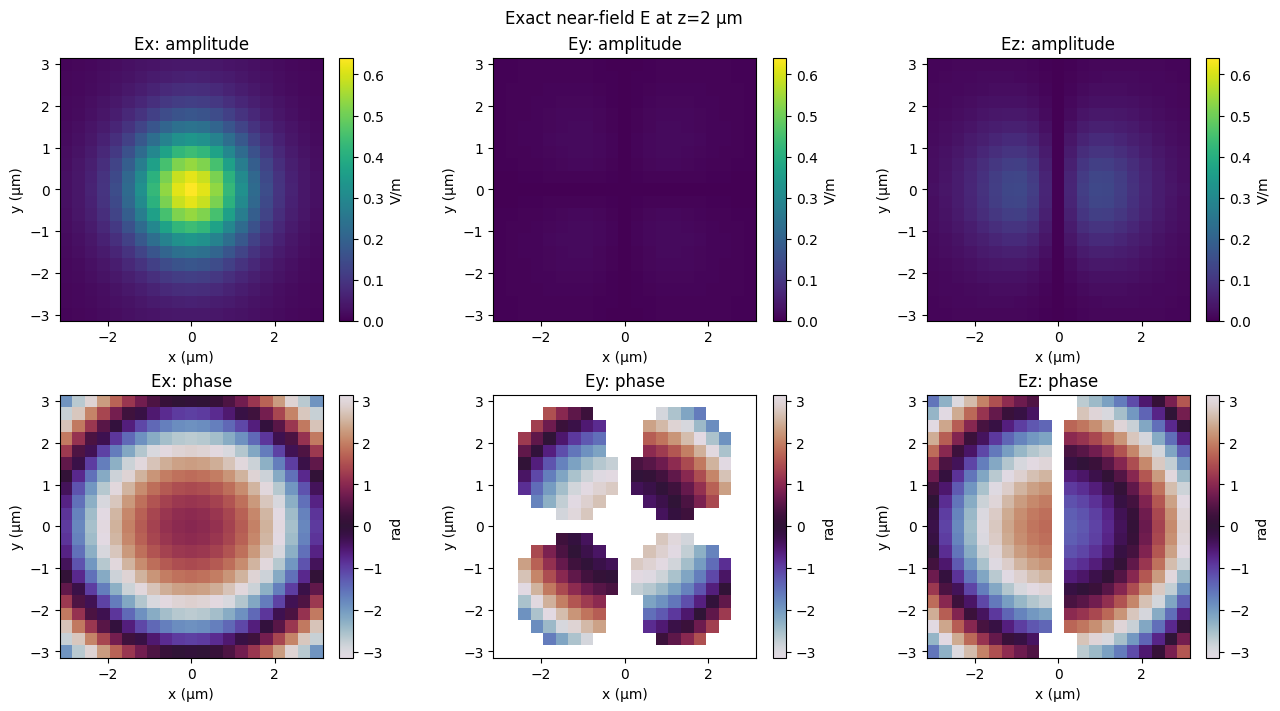

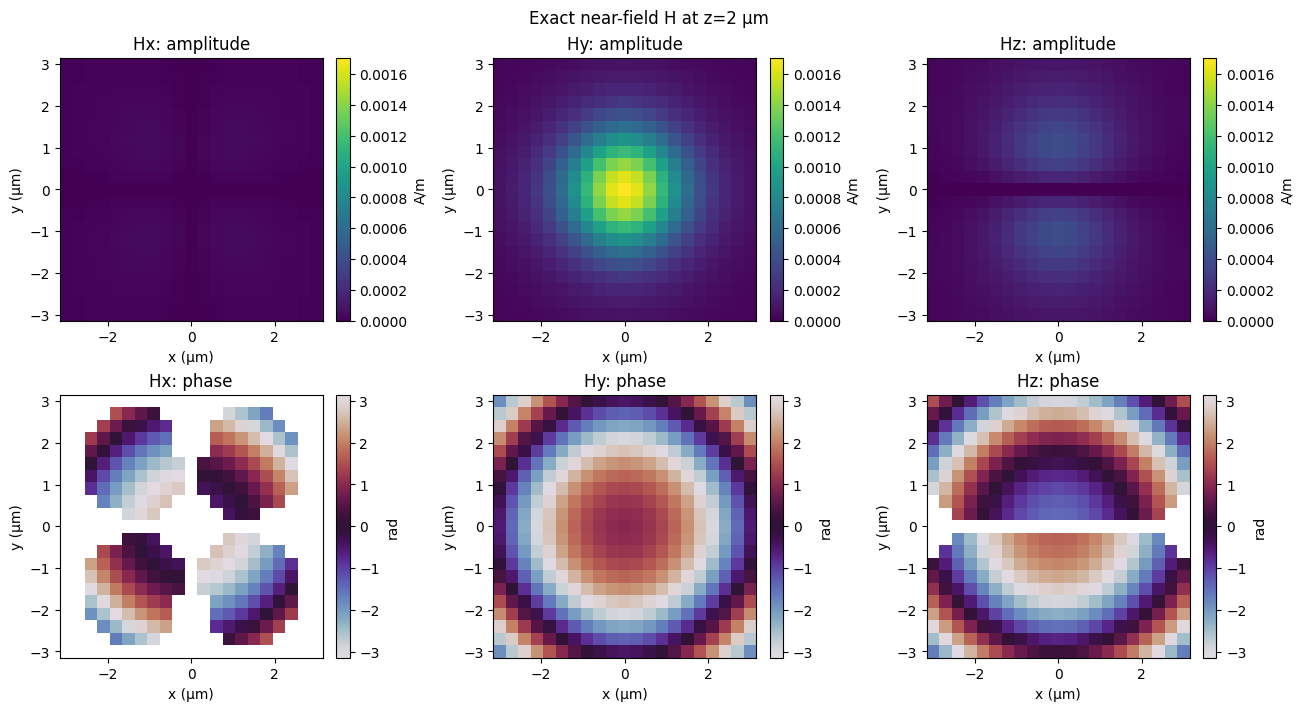

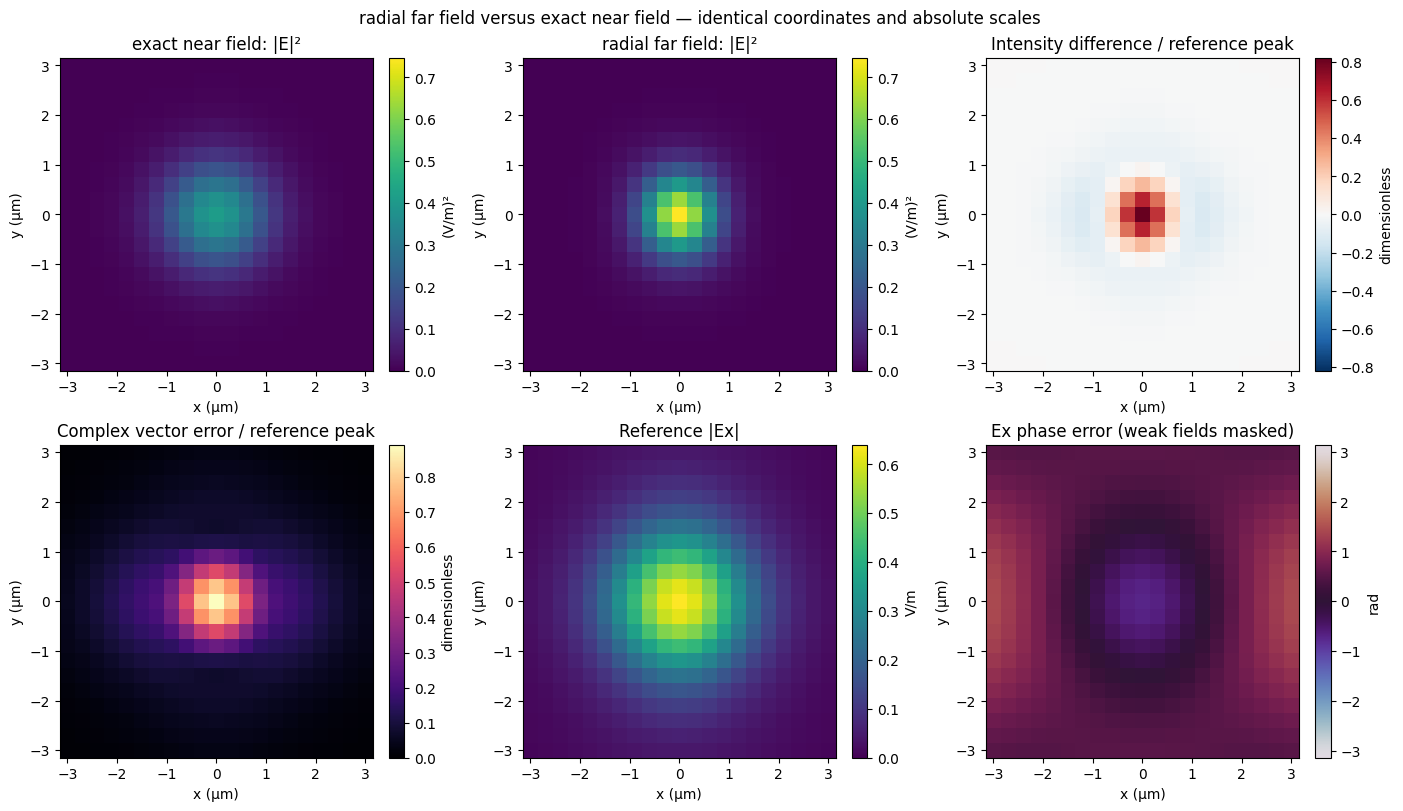

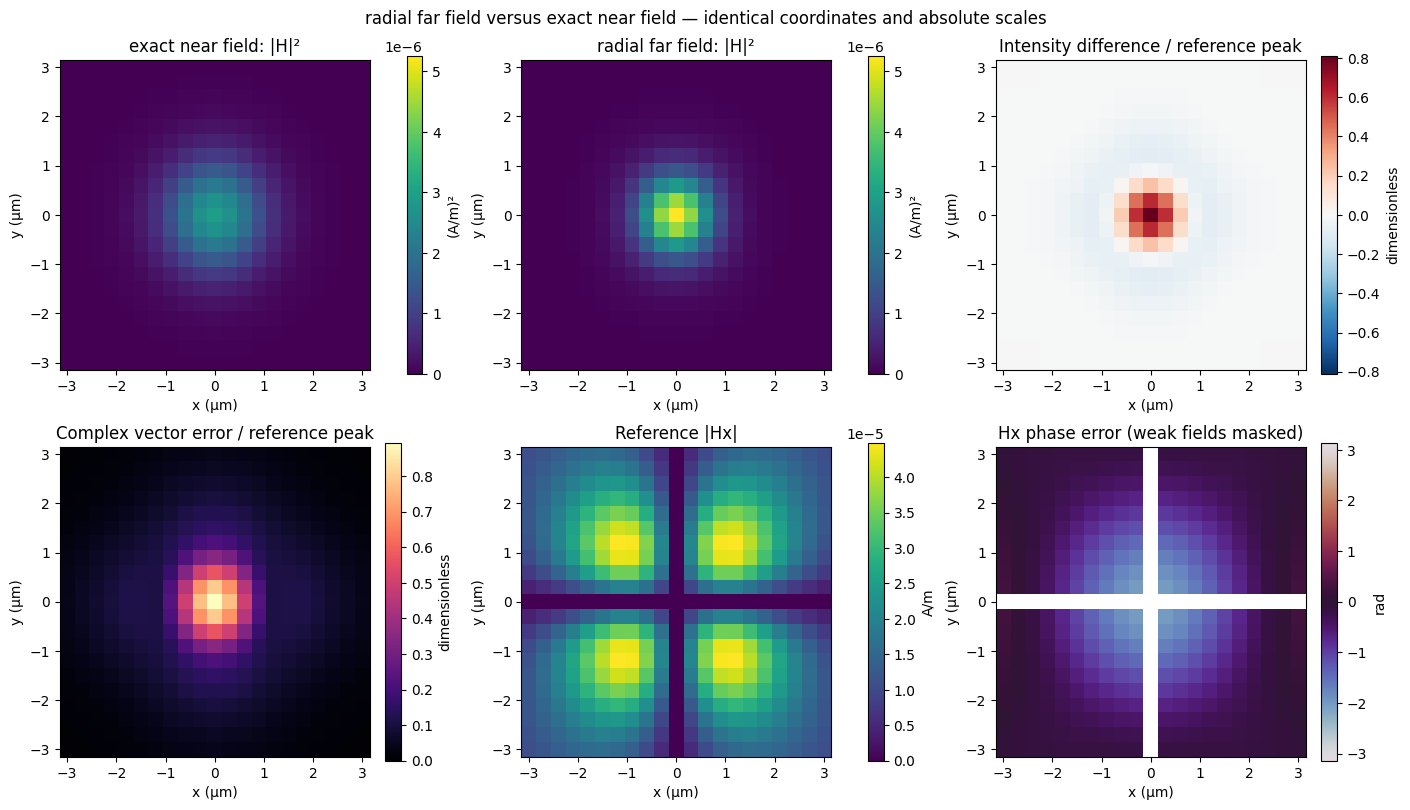

label,relative_complex_l2,relative_amplitude_l2,phase_rms_rad,strong_relative_l2,weak_absolute_over_peak,strong_count,weak_count
E at z=2 µm,0.54203,0.22211,0.65264,0.54203,N/A,441,0
H at z=2 µm,0.53849,0.21163,0.6294,0.53849,N/A,441,0


label,relative_complex_l2,relative_amplitude_l2,phase_rms_rad,strong_relative_l2,weak_absolute_over_peak,strong_count,weak_count
E z=0.75 µm,1.0087,0.68325,1.1636,1.0088,0.0054698,321,120
H z=0.75 µm,1.0121,0.67378,1.2134,1.0121,0.005577,315,126
E z=1.25 µm,0.76678,0.41825,0.85667,0.76678,0.0035716,437,4
H z=1.25 µm,0.76502,0.40513,0.8968,0.76503,0.0042579,429,12
E z=2 µm,0.54203,0.22211,0.65264,0.54203,N/A,441,0
H z=2 µm,0.53849,0.21163,0.6294,0.53849,N/A,441,0
E z=4 µm,0.29245,0.063502,0.45163,0.29245,N/A,441,0
H z=4 µm,0.28962,0.059768,0.43556,0.28962,N/A,441,0
E z=8 µm,0.17173,0.014929,0.33251,0.17173,N/A,441,0
H z=8 µm,0.17078,0.014447,0.32203,0.17078,N/A,441,0


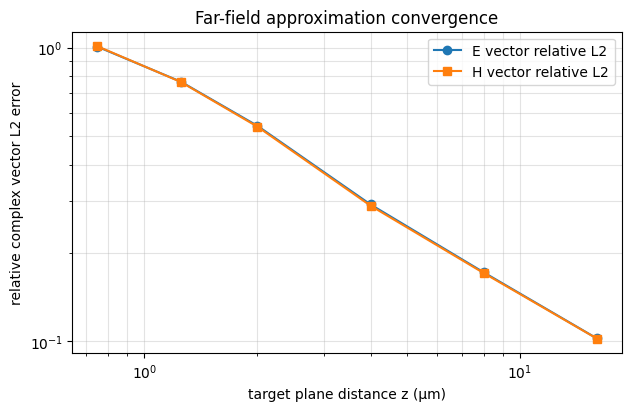

In [ ]:
# Plot exact components and method differences in Cartesian target-plane order.
_ = field_components(
    E_exact.reshape(target_n, target_n, 3),
    plane_axis_m.cpu().numpy() * 1e6,
    plane_axis_m.cpu().numpy() * 1e6,
    title=f"Exact near-field E at z={DISTANCE_UM:g} µm",
    quantity="E",
    units="V/m",
)
_ = field_components(
    H_exact.reshape(target_n, target_n, 3),
    plane_axis_m.cpu().numpy() * 1e6,
    plane_axis_m.cpu().numpy() * 1e6,
    title=f"Exact near-field H at z={DISTANCE_UM:g} µm",
    quantity="H",
    units="A/m",
)
_ = field_comparison(
    E_exact.reshape(target_n, target_n, 3),
    E_radial.reshape(target_n, target_n, 3),
    plane_axis_m.cpu().numpy() * 1e6,
    plane_axis_m.cpu().numpy() * 1e6,
    names=("exact near field", "radial far field"),
    quantity="E",
    units="V/m",
)
_ = field_comparison(
    H_exact.reshape(target_n, target_n, 3),
    H_radial.reshape(target_n, target_n, 3),
    plane_axis_m.cpu().numpy() * 1e6,
    plane_axis_m.cpu().numpy() * 1e6,
    names=("exact near field", "radial far field"),
    quantity="H",
    units="A/m",
)
show_errors(
    [
        error_summary(E_exact, E_radial, label=f"E at z={DISTANCE_UM:g} µm"),
        error_summary(H_exact, H_radial, label=f"H at z={DISTANCE_UM:g} µm"),
    ]
)

# Keep target point count modest so the default convergence sweep remains practical on CPU.
sweep_um = [0.75, 1.25, 2.0, 4.0, 8.0, 16.0]
sweep_records = []
e_values, h_values = [], []
for distance_um in sweep_um:
    _, ee, hh, er, hr = compare_plane(distance_um * 1e-6)
    sweep_records.append(error_summary(ee, er, label=f"E z={distance_um:g} µm"))
    sweep_records.append(error_summary(hh, hr, label=f"H z={distance_um:g} µm"))
    e_values.append(float((ee - er).norm().item() / max(ee.norm().item(), 1e-300)))
    h_values.append(float((hh - hr).norm().item() / max(hh.norm().item(), 1e-300)))
show_errors(sweep_records)
# Plot relative errors against distance. Errors use unscaled physical fields and are not fit to zero.
fig, ax = plt.subplots(figsize=(6.2, 4.0), constrained_layout=True)
ax.loglog(sweep_um, e_values, "o-", label="E vector relative L2")
ax.loglog(sweep_um, h_values, "s-", label="H vector relative L2")
ax.set(
    xlabel="target plane distance z (µm)",
    ylabel="relative complex vector L2 error",
    title="Far-field approximation convergence",
)
ax.grid(True, which="both", alpha=0.35)
ax.legend()
plt.show()

method,device,dtype,output_shape,first_forward_ms,warm_forward_ms,first_gradient_forward_ms,first_backward_ms,warm_backward_ms,warm_forward_backward_ms,peak_allocated_mib,peak_increment_mib,warmups,repeats
exact Torch near,cuda,torch.complex128,"(1, 441, 3)",51.367,52.604,1076,56.75,43.952,99.532,17.409,8.9385,1,3
radial far approximation,cuda,torch.complex128,"(1, 441, 3)",18.649,17.261,15.554,5.6298,3.301,19.1,20.514,12.043,1,3


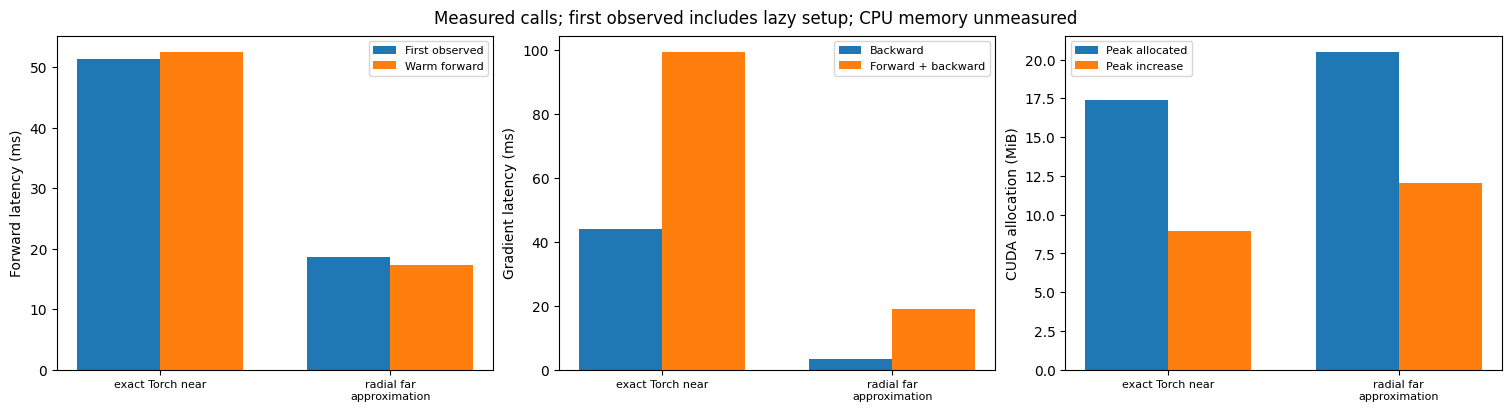

label,relative_complex_l2,relative_amplitude_l2,phase_rms_rad,strong_relative_l2,weak_absolute_over_peak,strong_count,weak_count
Torch c64 vs Triton c64 E,3.168e-07,1.9761e-07,4.0213e-07,3.168e-07,N/A,441,0
Torch c64 vs Triton c64 H,3.2003e-07,1.9711e-07,4.0088e-07,3.2003e-07,N/A,441,0


method,device,dtype,output_shape,first_forward_ms,warm_forward_ms,first_gradient_forward_ms,first_backward_ms,warm_backward_ms,warm_forward_backward_ms,peak_allocated_mib,peak_increment_mib,warmups,repeats
exact Torch c64,cuda,torch.complex64,"(1, 441, 3)",25.366,24.725,30.984,16.107,12.881,38.334,35.055,18.346,1,3
exact Triton c64,cuda,torch.complex64,"(1, 441, 3)",19.223,17.296,24.07,72.153,69.456,89.117,25.577,8.8677,1,3


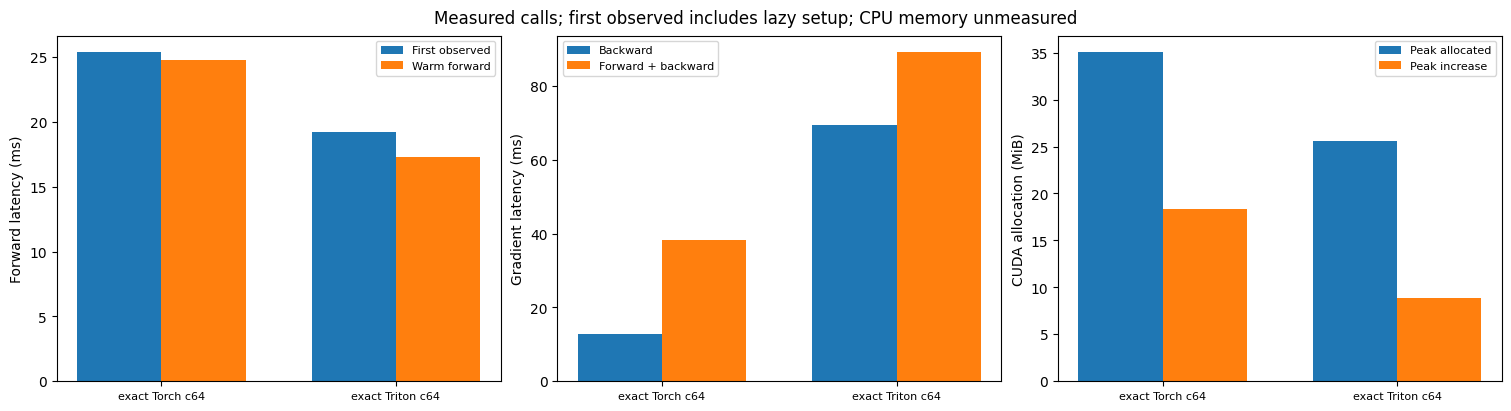

In [ ]:
# Current-run runtime and memory, including a backward pass through surface fields.
bench_surface = surface_copy(surface, requires_grad=True)
bench_targets = torch.stack((x_t, y_t, torch.full_like(x_t, 4.0e-6)), dim=-1).reshape(
    -1, 3
)
bench_radii = torch.linalg.vector_norm(bench_targets, dim=-1)
bench_directions = bench_targets / bench_radii[:, None]
bench_radial = torch.exp(1j * K[0] * bench_radii) / bench_radii


def benchmark_radial_farfield():
    """Return far-zone approximations at the same finite-distance targets."""
    ec, hc = project_farfield(bench_surface, bench_directions)
    return ec * bench_radial[None, :, None], hc * bench_radial[None, :, None]


bench_methods = {
    "exact Torch near": lambda: project_nearfield(
        bench_surface, bench_targets, source_chunk_size=128, observation_chunk_size=128
    ),
    "radial far approximation": benchmark_radial_farfield,
}
records = benchmark_methods(
    bench_methods,
    device=DEVICE,
    backward_inputs=(bench_surface.electric_fields, bench_surface.magnetic_fields),
)
show_benchmarks(records)

# Triton is an optional complex64 exact-backend check, separate from the physical asymptotic comparison.
if DEVICE.type == "cuda":
    try:
        from core.nearfield.triton_backend import project_nearfield_triton

        surface32 = surface_copy(surface, dtype=torch.complex64, requires_grad=True)
        targets32 = bench_targets.to(dtype=torch.float32)
        E_torch32, H_torch32 = project_nearfield(surface32, targets32)
        E_triton32, H_triton32 = project_nearfield_triton(surface32, targets32)
        show_errors(
            [
                error_summary(E_torch32, E_triton32, label="Torch c64 vs Triton c64 E"),
                error_summary(H_torch32, H_triton32, label="Torch c64 vs Triton c64 H"),
            ]
        )
        triton_records = benchmark_methods(
            {
                "exact Torch c64": lambda: project_nearfield(surface32, targets32),
                "exact Triton c64": lambda: project_nearfield_triton(
                    surface32, targets32
                ),
            },
            device=DEVICE,
            backward_inputs=(surface32.electric_fields, surface32.magnetic_fields),
        )
        show_benchmarks(triton_records)
    except (ImportError, RuntimeError, NotImplementedError) as exc:
        print(f"Triton exact backend comparison skipped: {type(exc).__name__}: {exc}")
else:
    print("Triton exact backend comparison skipped: CUDA is unavailable.")